# Simulating the effect of breathing exercises on stress

In [31]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


INFERENCE MODEL SPECIFICATIONS

WITHOUT WEEKDAY WEAKLY
  Name: Without Weekday - Weakly Informative
  Mean shape: (2,)
  V shape: (2, 2)
  V diagonal: 100.00
  Alpha: 1.00
  Beta: 1.00
  Prior means: [0. 0.]

WITHOUT WEEKDAY HIGHLY
  Name: Without Weekday - Highly Informative
  Mean shape: (2,)
  V shape: (2, 2)
  V diagonal: 1.00
  Alpha: 5.00
  Beta: 16.00
  Prior means: [-3.7 -3.7]

WITH WEEKDAY WEAKLY
  Name: With Weekday - Weakly Informative
  Mean shape: (9,)
  V shape: (9, 9)
  V diagonal: 100.00
  Alpha: 1.00
  Beta: 1.00
  Categorical covariates: {'L': 7}
  Prior means: [0. 0. 0. 0. 0. 0. 0. 0. 0.]

WITH WEEKDAY HIGHLY
  Name: With Weekday - Highly Informative
  Mean shape: (9,)
  V shape: (9, 9)
  V diagonal: 1.00
  Alpha: 5.00
  Beta: 16.00
  Categorical covariates: {'L': 7}
  Prior means: [ 0.   0.  -3.7 -0.5 -0.5 -0.5 -0.5  0.5  1. ]
Running Sklearn Simulation...


100%|██████████| 200/200 [00:13<00:00, 15.12it/s]


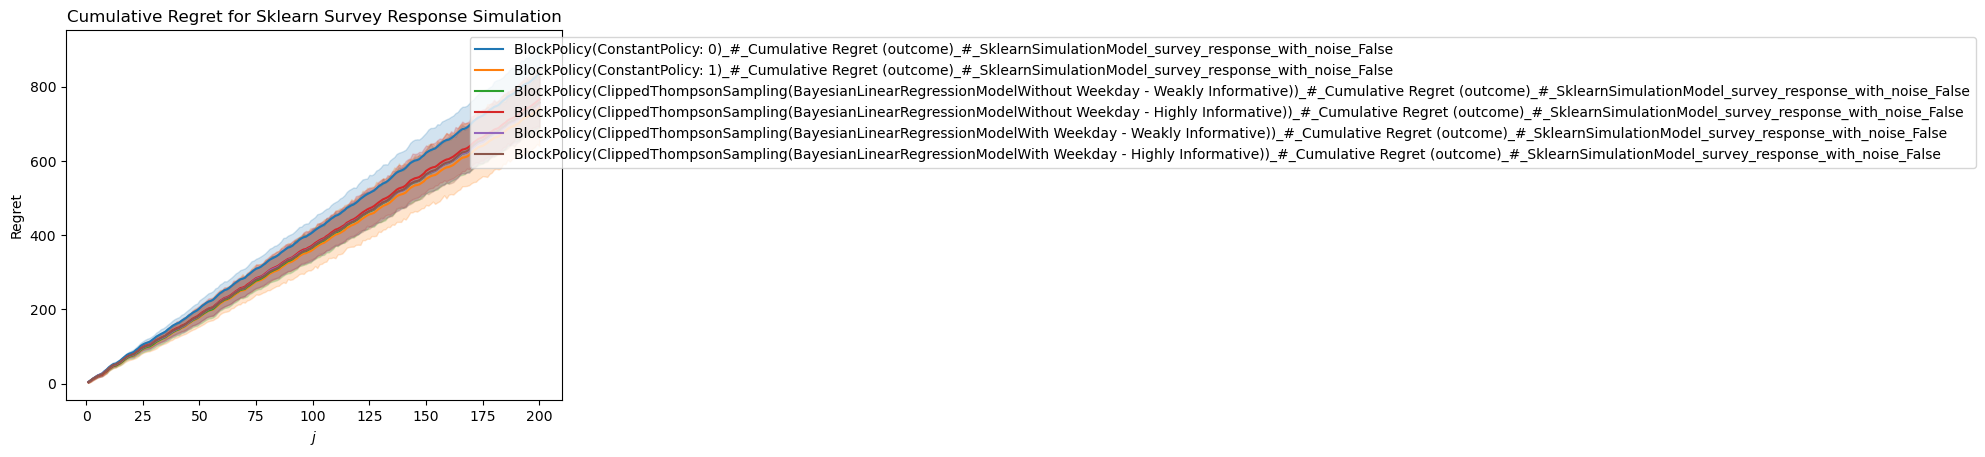

In [32]:
import numpy
import torch
import seaborn
from adaptive_nof1 import *
from adaptive_nof1.policies import *
from adaptive_nof1.helpers import *
from adaptive_nof1.inference import *
from adaptive_nof1.metrics import *
from adaptive_nof1.models import *
from matplotlib import pyplot as plt
from adaptive_nof1.patient_explorer import show_patient_explorer
import pandas

# Import the new SklearnSimulationModel
from adaptive_nof1.models.sklearn_simulation_model import SklearnSimulationModel

# Path to the saved survey response predictor model
model_path = '../models/survey_response_predictor'

# Initial parameters for simulation
block_length = 1
length = 200 * block_length
number_of_actions = 2
number_of_patients = 10

# Define prior specifications
WEAKLY_INFORMATIVE = {
    'cov_diag': 100.0,  # Large covariance = high uncertainty
    'alpha': 1.0,  # Vague prior on variance
    'beta': 1.0,  # Vague prior on variance
}

HIGHLY_INFORMATIVE = {
    'cov_diag': 1.0,  # Small covariance = low uncertainty
    'alpha': 5.0,  # More informative prior on variance
    'beta': 16.0,  # More informative prior on variance (E[σ²] = 16/4 = 4)
}

# Informative weekday means from data analysis
# Monday is the intercept (baseline = 3.7), so we only have 6 weekday coefficients
# Order: Tuesday, Wednesday, Thursday, Friday, Saturday, Sunday
WEEKDAY_INFORMATIVE_MEANS = numpy.array([
    -0.5,   # Tuesday
    -0.5,   # Wednesday
    -0.5,   # Thursday
    -0.5,   # Friday
    +0.5,  # Saturday
    +1.0   # Sunday
])

# Intercept (Monday baseline) mean
INTERCEPT_INFORMATIVE_MEAN = -3.7

# Informative treatment means for "without weekday" case
# Based on overall response levels from data analysis
# Treatment 0 (baseline/no treatment): overall mean response
# Treatment 1 (treatment): baseline + small treatment effect
TREATMENT_0_INFORMATIVE_MEAN = -3.7  # Overall baseline (similar to Monday intercept)
TREATMENT_1_INFORMATIVE_MEAN = -3.7  # No treatment effect assumed (can be adjusted based on data)

# Create inference models dynamically
def create_inference_model(include_weekday=True, informative='weakly'):
    """
    Create a BayesianLinearRegressionModel with specified priors.
    
    Parameters:
    -----------
    include_weekday : bool
        If True, include weekday as a categorical covariate
    informative : str
        'weakly' for weakly informative priors, 'highly' for highly informative priors
    
    Returns:
    --------
    BayesianLinearRegressionModel
    """
    # Select prior specification
    if informative == 'weakly':
        prior_spec = WEAKLY_INFORMATIVE
        prior_mean_intercept = 0.0  # Centered at zero
        prior_means_treatment = numpy.array([0.0, 0.0])  # Centered at zero
        prior_means_weekday = numpy.zeros(6)  # 6 weekdays (Tuesday-Sunday), Monday is intercept
    elif informative == 'highly':
        prior_spec = HIGHLY_INFORMATIVE
        prior_mean_intercept = INTERCEPT_INFORMATIVE_MEAN  # Monday baseline from data
        # For "without weekday": use informative treatment means
        # For "with weekday": treatments stay at zero (weekday effects capture the variation)
        if include_weekday:
            prior_means_treatment = numpy.array([0.0, 0.0])  # No informative prior for treatments
        else:
            prior_means_treatment = numpy.array([
                TREATMENT_0_INFORMATIVE_MEAN,  # Treatment 0 baseline
                TREATMENT_1_INFORMATIVE_MEAN  # Treatment 1
            ])
        prior_means_weekday = WEEKDAY_INFORMATIVE_MEANS  # Use data-informed means (Tuesday-Sunday)
    else:
        raise ValueError(f"informative must be 'weakly' or 'highly', got '{informative}'")
    
    # Build model name
    weekday_str = "With Weekday" if include_weekday else "Without Weekday"
    informative_str = "Highly Informative" if informative == 'highly' else "Weakly Informative"
    model_name = f"{weekday_str} - {informative_str}"
    
    if include_weekday:
        # Design matrix structure: Treatment (2) + Weekday dummies (7)
        # Monday is the intercept/baseline, so its effect is captured in the treatment coefficients
        # Order: [treatment_0, treatment_1, Monday, Tuesday, Wednesday, Thursday, Friday, Saturday, Sunday]
        # For Monday (baseline), use intercept mean; for others, use weekday means relative to Monday
        if informative == 'highly':
            # Monday gets the intercept mean (3.7), others get relative means
            weekday_means_with_monday = numpy.concatenate([[prior_mean_intercept], prior_means_weekday])
        else:
            # Weakly informative: all zeros
            weekday_means_with_monday = numpy.zeros(7)
        
        mean = numpy.concatenate([prior_means_treatment, weekday_means_with_monday])
        v = numpy.eye(9) * prior_spec['cov_diag']
        
        return BayesianLinearRegressionModel(
            mean=mean,
            v=v,
            alpha=prior_spec['alpha'],
            beta=prior_spec['beta'],
            covariate_names=[],
            categorical_covariates={"L": 7},  # 7 days of the week (Monday is baseline/intercept)
            name=model_name
        )
    else:
        # Only treatment (2 coefficients)
        mean = prior_means_treatment
        v = numpy.eye(2) * prior_spec['cov_diag']
        
        return BayesianLinearRegressionModel(
            mean=mean,
            v=v,
            alpha=prior_spec['alpha'],
            beta=prior_spec['beta'],
            covariate_names=[],
            name=model_name
        )

# Create all 4 inference models
inference_models = {
    'without_weekday_weakly': create_inference_model(include_weekday=False, informative='weakly'),
    'without_weekday_highly': create_inference_model(include_weekday=False, informative='highly'),
    'with_weekday_weakly': create_inference_model(include_weekday=True, informative='weakly'),
    'with_weekday_highly': create_inference_model(include_weekday=True, informative='highly'),
}

# Print model specifications
print("=" * 80)
print("INFERENCE MODEL SPECIFICATIONS")
print("=" * 80)
for key, model in inference_models.items():
    print(f"\n{key.upper().replace('_', ' ')}")
    print(f"  Name: {model.name}")
    print(f"  Mean shape: {model.mean.shape}")
    print(f"  V shape: {model.v.shape}")
    print(f"  V diagonal: {numpy.diag(model.v)[0]:.2f}")
    print(f"  Alpha: {model.alpha:.2f}")
    print(f"  Beta: {model.beta:.2f}")
    if hasattr(model, 'categorical_covariates') and model.categorical_covariates:
        print(f"  Categorical covariates: {model.categorical_covariates}")
    print(f"  Prior means: {model.mean}")

# Create scenarios using SklearnSimulationModel
sklearn_scenarios = {
    'sklearn_survey_response_with_noise': {
        'generator': lambda pid: SklearnSimulationModel(
            patient_id=pid, 
            model_path=model_path, 
            name='survey_response_with_noise',
            context_variance=0.0,
            outcome_variance=2.0, # 2.0 is realistic
            negate_output=True,
        ),
        'description': 'Survey Response Prediction with Weekday Context'
    }
}

# Define policies with all 4 inference models
sklearn_policies = [
    # Constant policies for baseline comparison
    BlockPolicy(
        block_length=block_length,
        internal_policy=ConstantPolicy(
            action=0  # Always choose action 0
        ),
    ),
    BlockPolicy(
        block_length=block_length,
        internal_policy=ConstantPolicy(
            action=1  # Always choose action 1
        ),
    ),
    
    # Thompson Sampling with all 4 inference model combinations
    BlockPolicy(
        block_length=block_length,
        internal_policy=ClippedThompsonSampling(
            inference_model=inference_models['without_weekday_weakly'],
        ),
    ),
    BlockPolicy(
        block_length=block_length,
        internal_policy=ClippedThompsonSampling(
            inference_model=inference_models['without_weekday_highly'],
        ),
    ),
    BlockPolicy(
        block_length=block_length,
        internal_policy=ClippedThompsonSampling(
            inference_model=inference_models['with_weekday_weakly'],
        ),
    ),
    BlockPolicy(
        block_length=block_length,
        internal_policy=ClippedThompsonSampling(
            inference_model=inference_models['with_weekday_highly'],
        ),
    ),
]

# Generate configurations
sklearn_study_designs = {
    "n_patients": [number_of_patients],
    "policy": sklearn_policies,
    "model_from_patient_id": [
        scenario['generator'] for scenario in sklearn_scenarios.values()
    ],
}

# Generate configuration cross product
sklearn_configurations = generate_configuration_cross_product(sklearn_study_designs)

# Run simulation
ENABLE_SIMULATION = True
if ENABLE_SIMULATION:
    print("Running Sklearn Simulation...")
    sklearn_calculated_series, sklearn_config_to_simulation_data = simulate_configurations(
        sklearn_configurations, length
    )
    
    # Optional: Save simulation results
    write_to_disk(
        "data/2025-12-18-sklearn_survey_response_simulation.json",
        [sklearn_calculated_series, sklearn_config_to_simulation_data],
    )

# Metrics for analysis
sklearn_metrics = [
    CumulativeRegret(),
]

# Analyze results
if ENABLE_SIMULATION:
    sklearn_df = SeriesOfSimulationsData.score_data(
        [s["result"] for s in sklearn_calculated_series],
        sklearn_metrics,
        # {
        #     "model": lambda x: x.split('_')[-1], 
        #     "policy": lambda x: str(x).split('(')[0],
        # }
    )
    
    # Plot results
    ax = SeriesOfSimulationsData.plot_lines(
        [s["result"] for s in sklearn_calculated_series],
        [CumulativeRegret()],
        legend_position=(0.8, 1.0)
    )
    plt.title('Cumulative Regret for Sklearn Survey Response Simulation')
    plt.ylabel('Regret')
    plt.show()

In [33]:
plot_allocations_for_calculated_series(
    sklearn_calculated_series,
)

:Layout
   .HeatMap.I   :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.I   :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.II  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.II  :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.III :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.III :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.IV  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.IV  :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.V   :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.V   :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.VI  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.VI  :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]

REGRET DISTRIBUTION FOR EACH POLICY

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionModelWith Weekday - Highly Informative))
--------------------------------------------------------------------------------
  Number of simulations: 10
  Mean regret:           757.2022
  Median regret:         749.6558
  Std deviation:         121.8163
  Min regret:            616.8490
  Max regret:            1056.1221
  25th percentile:       668.9676
  75th percentile:       785.1996

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionModelWith Weekday - Weakly Informative))
--------------------------------------------------------------------------------
  Number of simulations: 10
  Mean regret:           754.2758
  Median regret:         745.1079
  Std deviation:         109.7107
  Min regret:            633.3212
  Max regret:            1031.1656
  25th percentile:       674.3726
  75th percentile:       776.4004

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionMod

/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_82113/379660223.py:105: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(regret_data, labels=policy_names, patch_artist=True, vert=True)
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_82113/379660223.py:115: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right')
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_82113/379660223.py:118: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


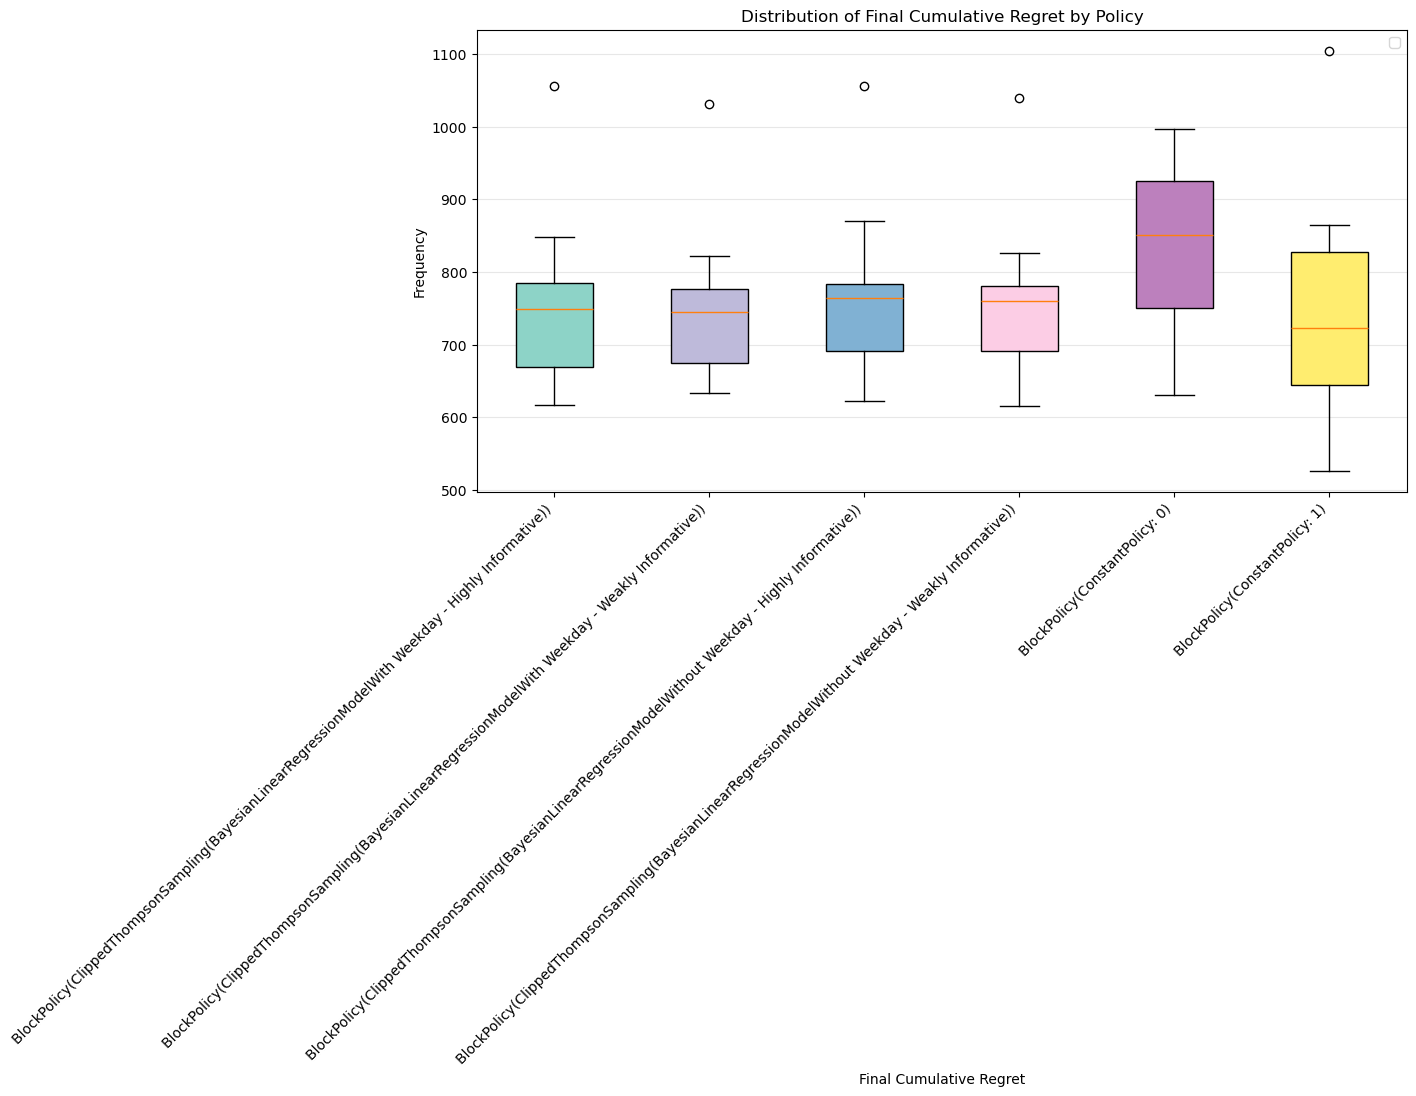

In [34]:
print("=" * 80)
print("REGRET DISTRIBUTION FOR EACH POLICY")
print("=" * 80)

# Use the already calculated sklearn_df which has regret scores
# Get the final cumulative regret (last time point) for each simulation
policy_regret_dict = {}

# Get the maximum time point (final regret)
if 't' in sklearn_df.columns and 'score' in sklearn_df.columns:
    max_t = sklearn_df['t'].max()
    final_regret_df = sklearn_df[sklearn_df['t'] == max_t]
    
    # Group by policy and extract regret scores
    for policy_name in final_regret_df['policy'].unique():
        policy_data = final_regret_df[final_regret_df['policy'] == policy_name]
        # Get the regret scores - score column contains arrays/lists, get the last value
        regret_values = []
        for score_val in policy_data['score'].values:
            if hasattr(score_val, '__iter__') and not isinstance(score_val, str):
                # If it's an array/list, get the last element
                try:
                    regret_values.append(float(score_val[-1]))
                except (IndexError, TypeError):
                    # If indexing fails, try to convert directly
                    try:
                        regret_values.append(float(score_val))
                    except (TypeError, ValueError):
                        pass
            else:
                # If it's a scalar, use it directly
                try:
                    regret_values.append(float(score_val))
                except (TypeError, ValueError):
                    pass
        policy_regret_dict[policy_name] = regret_values
else:
    # Fallback: calculate regret directly from simulations
    regret_metric = CumulativeRegret()
    for series in sklearn_calculated_series:
        policy_name = str(series["configuration"]["policy"]).split('(')[0]
        regret_values = []
        
        for simulation in series["result"].simulations:
            if len(simulation.history.observations) > 0:
                # Use score_simulations which takes a list
                regret_df = regret_metric.score_simulations([simulation])
                if 'score' in regret_df.columns and len(regret_df) > 0:
                    # score column contains arrays, get the last value from the last row
                    last_score = regret_df['score'].iloc[-1]
                    if hasattr(last_score, '__iter__') and not isinstance(last_score, str):
                        # Get the last element of the array
                        regret_values.append(float(last_score[-1]))
                    else:
                        regret_values.append(float(last_score))
        
        if policy_name not in policy_regret_dict:
            policy_regret_dict[policy_name] = []
        policy_regret_dict[policy_name].extend(regret_values)

# Print statistics for each policy
for policy_name, regret_values in sorted(policy_regret_dict.items()):
    if len(regret_values) > 0:
        regret_array = numpy.array(regret_values)
        print(f"\n{policy_name}")
        print("-" * 80)
        print(f"  Number of simulations: {len(regret_values)}")
        print(f"  Mean regret:           {numpy.mean(regret_array):.4f}")
        print(f"  Median regret:         {numpy.median(regret_array):.4f}")
        print(f"  Std deviation:         {numpy.std(regret_array):.4f}")
        print(f"  Min regret:            {numpy.min(regret_array):.4f}")
        print(f"  Max regret:            {numpy.max(regret_array):.4f}")
        print(f"  25th percentile:       {numpy.percentile(regret_array, 25):.4f}")
        print(f"  75th percentile:       {numpy.percentile(regret_array, 75):.4f}")

# Create a summary DataFrame
summary_data = []
for policy_name, regret_values in sorted(policy_regret_dict.items()):
    if len(regret_values) > 0:
        regret_array = numpy.array(regret_values)
        summary_data.append({
            'Policy': policy_name,
            'Mean': numpy.mean(regret_array),
            'Median': numpy.median(regret_array),
            'Std': numpy.std(regret_array),
            'Min': numpy.min(regret_array),
            'Max': numpy.max(regret_array),
            'Q25': numpy.percentile(regret_array, 25),
            'Q75': numpy.percentile(regret_array, 75),
            'N': len(regret_values)
        })

if summary_data:
    summary_df = pandas.DataFrame(summary_data)
    print("\n" + "=" * 80)
    print("SUMMARY TABLE")
    print("=" * 80)
    print(summary_df.to_string(index=False))
    
    # Plot box plots of regret distributions
    fig, ax = plt.subplots(figsize=(12, 6))
    regret_data = [policy_regret_dict[policy] for policy in sorted(policy_regret_dict.keys())]
    policy_names = sorted(policy_regret_dict.keys())
    
    bp = ax.boxplot(regret_data, labels=policy_names, patch_artist=True, vert=True)
    
    # Color the boxes
    colors = plt.cm.Set3(numpy.linspace(0, 1, len(bp['boxes'])))
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    
    ax.set_xlabel('Final Cumulative Regret')
    ax.set_ylabel('Frequency')
    ax.set_title('Distribution of Final Cumulative Regret by Policy')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3, axis='y')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

OUTCOME DISTRIBUTION FOR EACH POLICY

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionModelWith Weekday - Highly Informative))
--------------------------------------------------------------------------------
  Number of outcomes: 2000
  Mean outcome:       -3.7860
  Median outcome:     -3.7570
  Std deviation:      2.5147
  Min outcome:        -13.3860
  Max outcome:        4.4605

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionModelWith Weekday - Weakly Informative))
--------------------------------------------------------------------------------
  Number of outcomes: 2000
  Mean outcome:       -3.7714
  Median outcome:     -3.7559
  Std deviation:      2.4981
  Min outcome:        -13.3860
  Max outcome:        4.4605

BlockPolicy(ClippedThompsonSampling(BayesianLinearRegressionModelWithout Weekday - Highly Informative))
--------------------------------------------------------------------------------
  Number of outcomes: 2000
  Mean outcome:       -3.8277
  

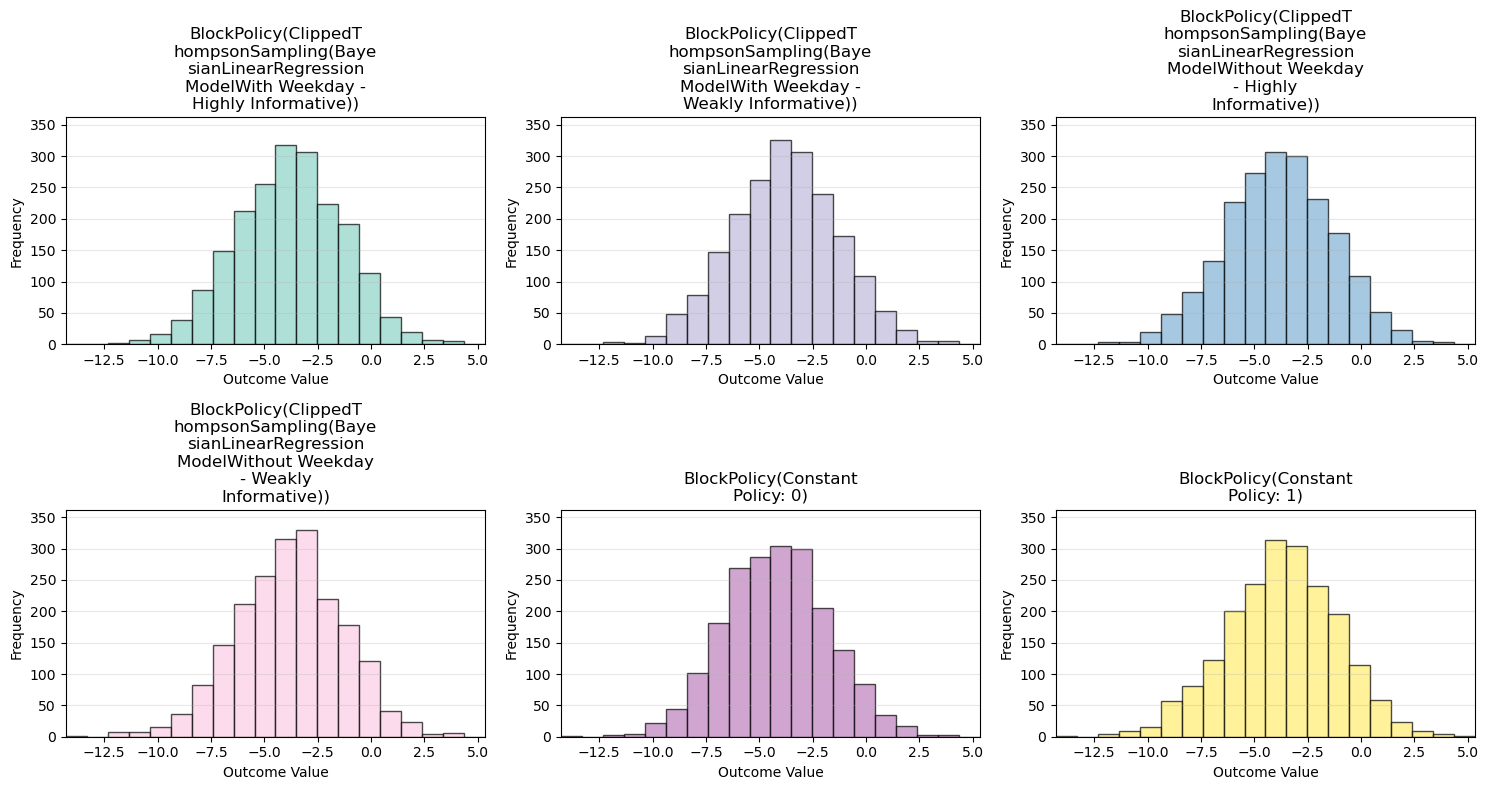

In [35]:
# Collect and plot outcomes as histograms with shared axes
if ENABLE_SIMULATION and 'sklearn_calculated_series' in locals():
    print("=" * 80)
    print("OUTCOME DISTRIBUTION FOR EACH POLICY")
    print("=" * 80)
    
    policy_outcome_dict = {}
    
    # Collect outcomes for each policy
    for series in sklearn_calculated_series:
        policy_name = str(series["configuration"]["policy"])
        outcomes = []
        
        for simulation in series["result"].simulations:
            for obs in simulation.history.observations:
                if "outcome" in obs.outcome:
                    outcomes.append(float(obs.outcome["outcome"]))
        
        if policy_name not in policy_outcome_dict:
            policy_outcome_dict[policy_name] = []
        policy_outcome_dict[policy_name].extend(outcomes)
    
    # Print statistics for each policy
    for policy_name, outcomes in sorted(policy_outcome_dict.items()):
        if len(outcomes) > 0:
            outcome_array = numpy.array(outcomes)
            print(f"\n{policy_name}")
            print("-" * 80)
            print(f"  Number of outcomes: {len(outcomes)}")
            print(f"  Mean outcome:       {numpy.mean(outcome_array):.4f}")
            print(f"  Median outcome:     {numpy.median(outcome_array):.4f}")
            print(f"  Std deviation:      {numpy.std(outcome_array):.4f}")
            print(f"  Min outcome:        {numpy.min(outcome_array):.4f}")
            print(f"  Max outcome:        {numpy.max(outcome_array):.4f}")
    
    # Plot individual histograms for each policy with shared axes
    outcome_data = [policy_outcome_dict[policy] for policy in sorted(policy_outcome_dict.keys())]
    policy_names = sorted(policy_outcome_dict.keys())
    
    # Determine shared axis limits
    all_outcomes = numpy.concatenate(outcome_data)
    x_min, x_max = all_outcomes.min(), all_outcomes.max()
    
    # Add padding to x-axis
    x_range = x_max - x_min
    x_min -= x_range * 0.05
    x_max += x_range * 0.05
    
    # Create subplots
    n_policies = len(policy_names)
    n_cols = 3
    n_rows = (n_policies + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
    if n_rows == 1 and n_cols == 1:
        axes = numpy.array([[axes]])
    elif n_rows == 1 or n_cols == 1:
        axes = axes.reshape(n_rows, n_cols)
    
    # Determine shared y-axis limit
    max_freq = 0
    for outcomes in outcome_data:
        counts, _ = numpy.histogram(outcomes, bins=20, range=(x_min, x_max))
        max_freq = max(max_freq, counts.max())
    
    # Plot each policy's histogram
    colors = plt.cm.Set3(numpy.linspace(0, 1, len(policy_names)))
    import textwrap
    for idx, (outcomes, policy_name, color) in enumerate(zip(outcome_data, policy_names, colors)):
        row = idx // n_cols
        col = idx % n_cols
        ax = axes[row, col]
        
        ax.hist(outcomes, bins=20, range=(x_min, x_max), color=color, edgecolor='black', alpha=0.7)
        ax.set_xlabel('Outcome Value')
        ax.set_ylabel('Frequency')
        wrapped_title = '\n'.join(textwrap.wrap(policy_name, width=20))
        ax.set_title(wrapped_title)
        ax.set_xlim(x_min, x_max)
        ax.set_ylim(0, max_freq * 1.1)
        ax.grid(True, alpha=0.3, axis='y')
    
    # Hide unused subplots
    for idx in range(n_policies, n_rows * n_cols):
        row = idx // n_cols
        col = idx % n_cols
        axes[row, col].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("Simulation results not available. Run the simulation first.")

In [36]:
df

,t,score,simulation,patient_id,model,policy,pooled,metric
199,199,996.422589,SimulationData,0,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,826.230347,SimulationData,1,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,874.868879,SimulationData,2,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,961.952342,SimulationData,3,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,911.515296,SimulationData,4,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,930.838705,SimulationData,5,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,734.161159,SimulationData,6,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,630.196597,SimulationData,7,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,684.298158,SimulationData,8,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,796.661300,SimulationData,9,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)


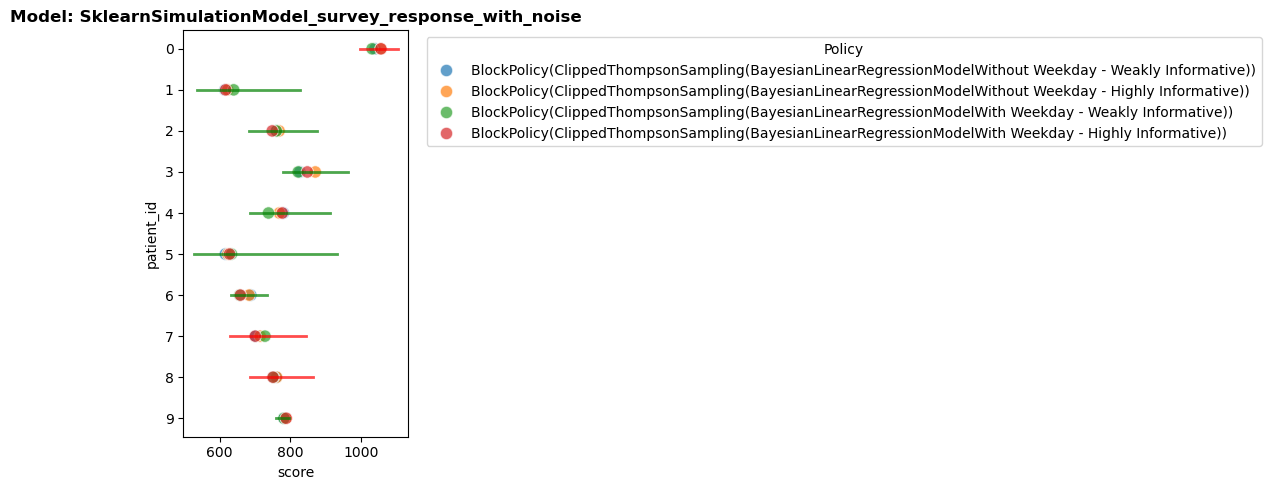

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

filtered_df = sklearn_df[sklearn_df["t"] == sklearn_df["t"].max()]

models = filtered_df["model"].unique()
n_cols = 2
n_rows = (len(models) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows))
axes = axes.flatten()

for idx, model in enumerate(models):
    df = filtered_df[filtered_df["model"] == model]
    
    # Scatterplot for other policies
    other_policies = df[~df["policy"].isin([
        "BlockPolicy(ConstantPolicy: 0)",
        "BlockPolicy(ConstantPolicy: 1)"
    ])]
    sns.scatterplot(data=other_policies, x="score", y="patient_id", 
                    hue="policy", ax=axes[idx], s=80, alpha=0.7)
    
    # Add lines for min/max block policies
    block_df = df[df["policy"].isin([
        "BlockPolicy(ConstantPolicy: 0)",
        "BlockPolicy(ConstantPolicy: 1)"
    ])]
    
    for patient_id in block_df["patient_id"].unique():
        patient_data = block_df[block_df["patient_id"] == patient_id]
        
        if len(patient_data) == 2:  # Both min and max exist
            min_score = patient_data[patient_data["policy"] == "BlockPolicy(ConstantPolicy: 0)"]["score"].values[0]
            max_score = patient_data[patient_data["policy"] == "BlockPolicy(ConstantPolicy: 1)"]["score"].values[0]
            
            # Determine color based on effect
            effect = min_score - max_score
            if effect > 1:
                color = 'green'  # Responder (positive effect)
            elif effect >= -1:
                color = 'grey'   # Neutral effect
            else:
                color = 'red'    # Negative effect
            
            # Draw line from min to max
            axes[idx].plot([min_score, max_score], [patient_id, patient_id], 
                          color=color, linewidth=2, alpha=0.7)
    
    axes[idx].set_title(f"Model: {model}", fontsize=12, fontweight='bold')
    axes[idx].legend(title="Policy", bbox_to_anchor=(1.05, 1), loc='upper left')

# Hide unused subplots
for idx in range(len(models), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

In [38]:
df

,t,score,simulation,patient_id,model,policy,pooled,metric
199,199,996.422589,SimulationData,0,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,826.230347,SimulationData,1,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,874.868879,SimulationData,2,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,961.952342,SimulationData,3,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,911.515296,SimulationData,4,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,930.838705,SimulationData,5,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,734.161159,SimulationData,6,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,630.196597,SimulationData,7,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,684.298158,SimulationData,8,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
199,199,796.661300,SimulationData,9,SklearnSimulationModel_survey_response_with_noise,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
